# Dynamic semiparametric ES, neural challengers and the comparative-backtest frame

- **Level:** 3, comparison with published methods
- **Prerequisites:** notebooks 04 and 05 of this topic (the ES backtests and the model comparison)
- **Reading time:** about 45 minutes

**Question:** Do the newest estimators of VaR and ES, the GAS-FZ models and CAViaR-ES, beat the econometric rungs of the ladder in six market windows, and does the engine's GARCH fit agree with the reference implementation?

## Objectives

By the end of this notebook you can:

- name the current academic methods for forecasting VaR and ES together, say what each one models, and say which of them the ladder runs and which it does not;
- state the comparative-backtest frame: why a validator asks whether a challenger beats the champion, and how Contraste answers it;
- read, from six committed market windows, how the dynamic semiparametric rungs and CAViaR-ES rank against the econometric ones, and test those differences with Diebold-Mariano and the model confidence set;
- read the record of how often those fits failed to converge, and say what that implies for using them;
- fit the product's GARCH-t on the committed realised returns with the engine and with the `arch` reference, and say what that check does and does not show.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2 arch==8.0.0 pandas==3.0.6 torch==2.14.1
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
import math
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv

for name in ("riskvalidation", "numpy", "scipy", "matplotlib", "arch", "pandas"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2
arch 8.0.0
pandas 3.0.6


## Data

The data is case C11: the ladder document `models-ladder.json` and the six window documents. For each rung and window they hold the VaR and ES forecasts, the mean FZ0 loss and the number of refits and convergence failures. Two windows (`fx-2008`, `rates-2022`) commit the realised losses, so the Diebold-Mariano comparisons of step 2 are recomputed there; the other four are read from the committed rows.

What this notebook **cannot** do, and says so. The estimators of this level (the GAS-FZ models and CAViaR) need at least 500 returns to fit, and no window commits its estimation returns (derived-only or 1,000 days outside the file), so they are not refitted here. The package `arch`, which the product uses for its GARCH rung and its own tests use as the reference, is installed here, so step 3 fits the GARCH-t on the two realised-return series that windows commit and compares the engine with a direct `arch` call. What it still cannot do is reproduce the committed GARCH-t forecasts: they were fitted on 1,000 estimation days that are not committed. The evidence for the ranks and tests of steps 1 and 2 is therefore the committed forecasts, which the engine computed and the artifacts record.

In [2]:
# Load the ladder document and the six windows of case C11, and list the rungs of the current levels
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
C11 = ROOT / "data" / "derived" / "C11"
NAMES = ("calm-2004-06", "equity-2007-09", "equity-2020", "rates-2022", "fx-2008", "mixed-2023")
docs = {w: json.loads((C11 / f"{w}.json").read_text(encoding="utf-8")) for w in NAMES}
ladder = json.loads((C11 / "models-ladder.json").read_text(encoding="utf-8"))["fit"]["ladder"]

print("riskvalidation", docs["fx-2008"]["provenance"]["riskvalidation_version"], "| installed", rv.__version__)
for entry in ladder:
    if entry["rung"] in ("R8", "R9", "R10"):
        print(f"{entry['model_id']:11s} {entry['rung']:4s} {entry['title']['en']}")

riskvalidation 1.0.1 | installed 1.0.1
caviar-sav  R8   CAViaR, symmetric absolute value
caviar-as   R8   CAViaR, asymmetric slope
caviar-es   R8   ES-CAViaR (two-step, Taylor)
gas-fz-1    R9   GAS-FZ, one factor
gas-fz-2    R9   GAS-FZ, two factors
gas-hybrid  R9   Hybrid GARCH-FZ
nn-fz       R10  Quantile network trained on FZ0 (challenger)


## Method

### Step 1: the comparative-backtest frame

A traditional backtest asks whether **the model** is acceptable: its null hypothesis is that the forecasts are correct (notebooks 03 and 04). Nolde and Ziegel (2017) point out that a regulator or a validator usually asks something else: is the internal model at least as good as a standard one? That is a **comparative backtest**: both models are scored with a consistent loss, here FZ0, and the null is that the first is no worse than the second. Contraste applies the frame in two steps (notebook 05): the traditional backtests decide eligibility, and the comparison by mean FZ0, Diebold-Mariano and the model confidence set ranks the eligible models.

Within this frame the question of this level is concrete: do the newest estimators, which model the VaR and the ES jointly and let them evolve with the data, rank above the econometric rungs? The first cell ranks, in each window at 1 percent, the 14 rungs that forecast an ES by their mean FZ0 (rank 1 is the lowest loss) and prints the rank of the four newest: `caviar-es`, `gas-fz-1`, `gas-fz-2` and `gas-hybrid`. Ranks are within a window; FZ0 levels are not comparable across windows. The two windows that commit their returns (`fx-2008` and `rates-2022`) are recomputed with the engine's `fz0_loss`; the four others are read from the committed mean FZ0.

In [3]:
# Rank the 14 rungs with an ES by mean FZ0 at 1% (1 is best) in each window, and print the rank of the four
# newest
from riskvalidation.market.scoring import fz0_loss

newest = ("caviar-es", "gas-fz-1", "gas-fz-2", "gas-hybrid")
ranks = {}
for window in NAMES:
    out = docs[window]["outputs"]
    committed = out["grid"]["realised_loss"]["status"] == "included"
    returns = -np.array(out["grid"]["realised_loss"]["loss"]) if committed else None
    scores = {}
    for model in out["models"]:
        level = model["by_level"][0]
        if level["fz0_mean"] is not None and level["n_fz0"] == level["n_scored"]:
            scores[model["model_id"]] = level["fz0_mean"]
            if committed:
                var, es = -np.array(level["var"]), -np.array(level["es"])
                scores[model["model_id"]] = fz0_loss(returns, var, es, 0.01).mean()
    order = sorted(scores, key=scores.get)
    ranks[window] = {m: order.index(m) + 1 for m in order}
    cells = " ".join(f"{ranks[window][m]:>7d}/{len(order)}" for m in newest)
    print(f"{window:15s} {cells}   {order[0]} ({scores[order[0]]:.3f})")

calm-2004-06          7/14      11/14      12/14      13/14   gjr-t (-4.521)
equity-2007-09        5/14      11/14      10/14      13/14   gjr-t (-2.876)
equity-2020           3/14       9/14      10/14       7/14   fhs (-1.986)
rates-2022            5/14      13/14      12/14      11/14   ewma (-3.811)
fx-2008               1/14      14/14      12/14      13/14   caviar-es (-3.557)
mixed-2023            7/14       9/14      11/14       8/14   gjr-t (-4.439)


The next cell draws the ranks of step 1: for each window the rank of the four newest rungs among the 14 with an ES, with the committed eligibility verdict marked. A low rank that comes from an ineligible model is not a champion (notebook 05), and the figure shows where the two differ.

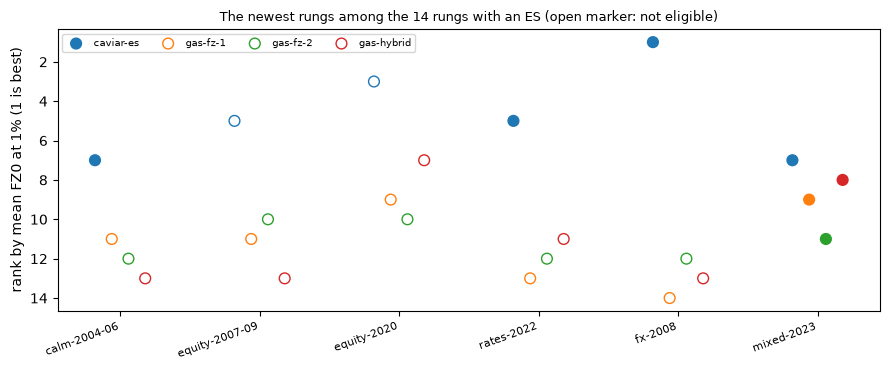

In [4]:
# Draw the rank of each newest rung in each window (1 is best); a filled marker is an eligible model, an
# open one is not
eligibility = {w: {m["model_id"]: m["eligible"] for m in docs[w]["outputs"]["models"]} for w in NAMES}
fig, ax = plt.subplots(figsize=(9, 3.8))
for offset, rung in enumerate(newest):
    xs = np.arange(len(NAMES)) + (offset - 1.5) * 0.12
    faces = [f"C{offset}" if eligibility[w][rung] else "none" for w in NAMES]
    ax.scatter(xs, [ranks[w][rung] for w in NAMES], s=60, label=rung, facecolors=faces, edgecolors=f"C{offset}")
ax.invert_yaxis()
ax.set_xticks(range(len(NAMES)), NAMES, rotation=20, ha="right", fontsize=8)
ax.set_ylabel("rank by mean FZ0 at 1% (1 is best)")
ax.set_title("The newest rungs among the 14 rungs with an ES (open marker: not eligible)", fontsize=9)
ax.legend(fontsize=7, ncol=4)
fig.tight_layout()
plt.show()

Each marker is the rank of one of the four newest rungs among the 14 with an ES in one window, at 1 percent, and a low position on the chart means a low loss. `caviar-es` sits between 1 and 7 in every window and is first in `fx-2008`, where it is the champion; the three GAS-FZ rungs sit between 7 and 14 everywhere, and none reaches the first six places of any window. The best rung changes with the window: `gjr-t` in three of them, `fhs` in `equity-2020`, `ewma` in `rates-2022` and `caviar-es` in `fx-2008`. An open marker is a model the gates removed, so a low rank on an open marker is not a champion. The figure ranks and does not test: how far apart two ranks are in loss is the question of the next step.

### Step 2: testing the difference, Diebold-Mariano against two econometric references

A rank is not a test. Where the realised losses are committed we can test the difference in mean FZ0 between a newest rung and an econometric reference with `diebold_mariano` (one-step forecasts, no lags). The references are `ewma` (the simple volatility model) and `evt-mf` (the conditional EVT rung); a positive statistic means the newest rung has the higher loss. The cell tests the four newest rungs against both references at 1 and 2.5 percent in `fx-2008` and `rates-2022` and counts the outcomes; the figure after it draws the 32 statistics.

In [5]:
# Diebold-Mariano of the four newest rungs against ewma and evt-mf on the FZ0 loss, in the windows with
# realised losses
from riskvalidation.market.scoring import diebold_mariano

references = ("ewma", "evt-mf")
cases = [(w, a) for w in ("fx-2008", "rates-2022") for a in (0.01, 0.025)]
pairs = [(rung, reference) for rung in newest for reference in references]
statistic, pvalue = np.zeros((len(pairs), len(cases))), np.ones((len(pairs), len(cases)))
for j, (window, alpha) in enumerate(cases):
    out = docs[window]["outputs"]
    y = -np.array(out["grid"]["realised_loss"]["loss"])
    levels = {m["model_id"]: [lv for lv in m["by_level"] if lv["alpha"] == alpha][0] for m in out["models"]}
    forecasts = {m: (-np.array(levels[m]["var"]), -np.array(levels[m]["es"])) for m in (*newest, *references)}
    loss_of = {m: fz0_loss(y, v, e, alpha) for m, (v, e) in forecasts.items()}
    for i, (rung, reference) in enumerate(pairs):
        result = diebold_mariano(loss_of[rung], loss_of[reference], 0)
        statistic[i, j], pvalue[i, j] = result.statistic, result.p_value
print(f"caviar-es: {(pvalue[:2] >= 0.05).sum()} of {pvalue[:2].size} comparisons indistinguishable")
print(f"GAS-FZ: {(statistic[2:] > 0).sum()} of {statistic[2:].size} with the higher loss, "
      f"{((statistic[2:] > 0) & (pvalue[2:] < 0.05)).sum()} significant")
print(f"newest significantly better: {((statistic < 0) & (pvalue < 0.05)).sum()}")

caviar-es: 8 of 8 comparisons indistinguishable
GAS-FZ: 24 of 24 with the higher loss, 12 significant
newest significantly better: 0


The figure draws the 32 Diebold-Mariano statistics, one row for each newest rung and reference and one column for each window and level; a star marks a p-value below 0.05 and red means the newest rung has the higher loss.

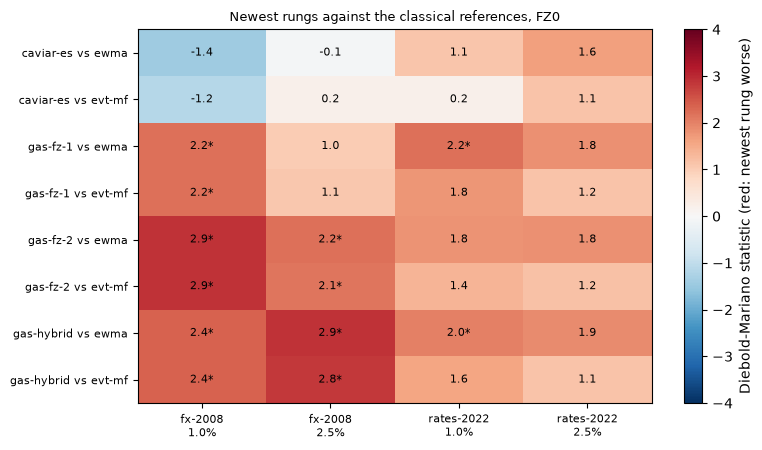

In [6]:
# Draw the Diebold-Mariano statistics of the newest rungs against the two references (a star marks p < 0.05)
labels = [f"{rung} vs {reference}" for rung, reference in pairs]
fig, ax = plt.subplots(figsize=(8, 4.6))
image = ax.imshow(statistic, cmap="RdBu_r", vmin=-4, vmax=4, aspect="auto")
ax.set_xticks(range(len(cases)), [f"{w}\n{a:.1%}" for w, a in cases], fontsize=8)
ax.set_yticks(range(len(labels)), labels, fontsize=8)
for i in range(len(labels)):
    for j in range(len(cases)):
        text = f"{statistic[i, j]:.1f}" + ("*" if pvalue[i, j] < 0.05 else "")
        ax.text(j, i, text, ha="center", va="center", fontsize=8)
fig.colorbar(image, ax=ax, label="Diebold-Mariano statistic (red: newest rung worse)")
ax.set_title("Newest rungs against the econometric references, FZ0", fontsize=9)
fig.tight_layout()
plt.show()

Red cells are comparisons in which the newest rung has the higher loss than the reference and blue cells the opposite. `caviar-es` has statistics between -1.4 and 1.6 and no star: it cannot be told apart from `ewma` or `evt-mf` in any of the 8 comparisons. The three GAS-FZ rungs have a positive statistic in all 24 comparisons and 12 of them carry a star: all six in `fx-2008` at 1 percent, four at 2.5 percent (`gas-fz-2` and `gas-hybrid`) and two in `rates-2022` at 1 percent against `ewma`. No cell is blue and starred, so no newest rung is significantly better than an econometric one. The figure shows the direction and the strength of each comparison; it does not show why the GAS-FZ rungs lose, and the record of their fits in the last figure is the first place to look.

## Comparison

The methods below are the current academic frontier for forecasting VaR and ES together, with their standing in the ladder.

| Method | What it models | In the ladder | Source |
|---|---|---|---|
| **GAS-FZ, one factor** | the VaR and ES as $v_t = a\,e^{\kappa_t}$, $e_t = b\,e^{\kappa_t}$ with $\kappa_{t+1} = \beta\kappa_t + \gamma\,(-1/e_t)\big(\tfrac1\alpha \mathbb 1\{y_t \le v_t\}y_t - e_t\big)$, estimated by minimising the average FZ0 loss | `gas-fz-1`, rung R9 | Patton, Ziegel and Chen (2019) |
| **GAS-FZ, two factors** | $(v, e)_{t+1} = w + B\,(v, e)_t + A\,(\lambda_v, \lambda_e)_t$, a score-driven recursion with its own factor per measure | `gas-fz-2`, rung R9 | Patton, Ziegel and Chen (2019) |
| **Hybrid GARCH-FZ** | the one-factor model plus a term $\delta\ln\lvert y_t\rvert$ added to the factor recursion | `gas-hybrid`, rung R9 | Patton, Ziegel and Chen (2019), equation 27 |
| **CAViaR-ES** | the VaR follows a CAViaR recursion; the ES is the VaR minus an autoregressive gap, by asymmetric Laplace likelihood | `caviar-es`, rung R8, estimated in **two steps** (the engine declares this as its deviation from Taylor's joint estimation) | Taylor (2019) |
| **Quantile and neural quantile models on the FZ loss** | return quantiles and ES from a network trained on FZ0; an active line of preprints | `nn-fz`, rung R10, **not run** | recent preprints (for example arXiv 2606.04576) |
| **Comparative backtest** | the frame of step 1: H0 is that the internal model is no worse than a standard one, under a consistent loss | the comparison of notebook 05 | Nolde and Ziegel (2017) |
| **Multinomial VaR backtests** | several VaR levels at once as an implicit ES backtest | **not in the engine** | Kratz, Lok and McNeil (2018) |

The honest standing of the neural line, as of the research behind this product, is that no regulator recognises it as a standard for internal models and its gains over a well-specified GARCH, EVT or GAS-FZ benchmark depend on the dataset. Contraste therefore treats it as a challenger only: it would have to enter the 90 percent confidence set on FZ0 **out of sample**, shown by Diebold-Mariano and the confidence set and not by in-sample fit. The ladder document records that `nn-fz` was not trained; nothing in the committed data evaluates a neural model, and this notebook does not claim that one would or would not do better.

The cells below run the model confidence set on the ladder, fit the product's GARCH-t against the `arch` reference and draw the committed record of how the newest fits behaved.

set: 13 of 14
outside the set: ['dn-rolling']
caviar-es   MCS p-value 1.000
gas-fz-1    MCS p-value 0.678
gas-fz-2    MCS p-value 0.493
gas-hybrid  MCS p-value 0.644


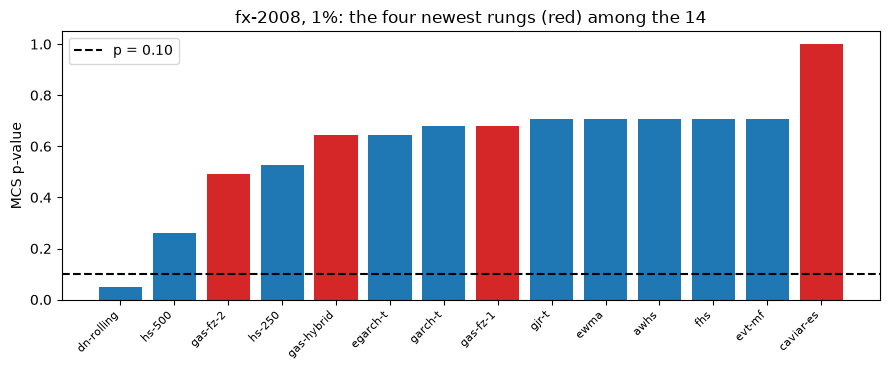

In [7]:
# Model confidence set of the 14 rungs with an ES in fx-2008 at 1% on the FZ0 loss, with the p-value of each
# rung drawn
from riskvalidation.market.scoring import model_confidence_set

fx = docs["fx-2008"]["outputs"]
y = -np.array(fx["grid"]["realised_loss"]["loss"])
setting = [m for m in fx["comparison"]["mcs"] if m["alpha"] == 0.01][0]
ids = [m["model_id"] for m in setting["members"]]
levels = {m["model_id"]: m["by_level"][0] for m in fx["models"]}
losses = np.column_stack([fz0_loss(y, -np.array(levels[i]["var"]), -np.array(levels[i]["es"]), 0.01) for i in ids])
args = (setting["confidence"], setting["statistic"], setting["n_bootstrap"], setting["block_length"], 42)
mcs = model_confidence_set(losses, *args)
print(f"set: {len(mcs.members)} of {len(ids)}")
print("outside the set:", [ids[i] for i in range(len(ids)) if i not in mcs.members])
for rung in newest:
    print(f"{rung:11s} MCS p-value {mcs.p_values[ids.index(rung)]:.3f}")

order = np.argsort(mcs.p_values)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(range(len(ids)), mcs.p_values[order], color=["tab:red" if ids[i] in newest else "tab:blue" for i in order])
ax.axhline(0.10, color="black", linestyle="--", label="p = 0.10")
ax.set_xticks(range(len(ids)), [ids[i] for i in order], rotation=45, ha="right", fontsize=8)
ax.set_ylabel("MCS p-value")
ax.set_title("fx-2008, 1%: the four newest rungs (red) among the 14")
ax.legend()
fig.tight_layout()
plt.show()

Each bar is the MCS p-value of one rung in `fx-2008` at 1 percent, and a rung is in the 90 percent set when its bar clears the dashed line at 0.10. Thirteen of the 14 rungs are in the set and only `dn-rolling` is outside. The four newest (red bars) are all inside: `caviar-es` with p of 1.000 as the lowest loss, `gas-fz-1` with 0.678, `gas-hybrid` with 0.644 and `gas-fz-2` with 0.493. The set and the pairwise tests of step 2 give different answers to different questions: the set asks which rungs cannot be excluded against the whole ladder, with a bootstrap over the range of losses, and it has less power than a pairwise test against one reference. The figure shows that the data of one year cannot exclude the GAS-FZ rungs from the set, even though two references beat them one by one.

### Step 3: the engine's GARCH-t fit against the `arch` reference

The product's GARCH rung is a quasi-maximum-likelihood fit of a GARCH(1,1) with Student-t innovations and a constant mean, and the engine runs it through the `arch` package (`riskvalidation.market.garch.fit_garch`). That has a consequence to say first: `arch` is the reference of the engine's own tests and not an independent re-implementation, so this check cannot find an error inside `arch`. It checks what the engine adds around the call: the scaling of the returns to percent and back to decimals, the shift of the log-likelihood by $n \ln 100$, the parameter names and the convergence verdict. Two cells fit the same committed returns three ways: with the engine; with a direct `arch.arch_model` call in percent whose parameters are brought back to decimals; and with `arch` again from a different starting point, which tests that the optimum belongs to the likelihood and not to the start.

The inputs are the 251 realised returns that `fx-2008` commits (a return is the loss with its sign changed). The engine needs at least 250 returns to fit, and `rates-2022` commits 249, so the second cell also shows the engine's refusal of that series. The tolerances are stated before the run. Engine against the direct `arch` call: relative difference below $10^{-9}$ (same optimiser and same start, so only the order of floating-point operations may differ). `arch` from the second start: log-likelihood within $10^{-6}$ and parameters within $10^{-3}$ relative (the optimiser stops at a tolerance, and a GARCH likelihood is flat near its optimum).

In [8]:
# Fit the GARCH-t of the engine and the arch reference on the 251 committed realised returns of fx-2008
import arch
from riskvalidation.market import garch

returns = y
engine_fit = garch.fit_garch(returns, "garch", "student-t", "constant")
model = arch.arch_model(returns * 100, mean="Constant", vol="GARCH", p=1, q=1, dist="t", rescale=False)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    reference = model.fit(disp="off", show_warning=False, update_freq=0)
scale = {"mu": 100, "omega": 100 ** 2, "alpha[1]": 1, "beta[1]": 1, "nu": 1}
print(f"{'parameter':10s} {'engine':>14s} {'arch':>14s} {'relative difference':>22s}")
for name, factor in scale.items():
    value = reference.params[name] / factor
    relative = abs(engine_fit.params[name] / value - 1)
    print(f"{name:10s} {engine_fit.params[name]:14.8g} {value:14.8g} {relative:22.2e}")
arch_ll = reference.loglikelihood + len(returns) * math.log(100)
print(f"log-likelihood: engine {engine_fit.log_likelihood:.6f} | arch {arch_ll:.6f}")
print(f"engine converged: {'yes' if engine_fit.converged else 'no'} | arch flag {reference.convergence_flag}")

parameter          engine           arch    relative difference
mu         -0.00075822796 -0.00075822796               0.00e+00
omega       1.8944118e-06  1.8944118e-06               0.00e+00
alpha[1]      0.044303998    0.044303998               0.00e+00
beta[1]        0.94373067     0.94373067               0.00e+00
nu              5.2144163      5.2144163               0.00e+00
log-likelihood: engine 803.654204 | arch 803.654204
engine converged: yes | arch flag 0


The second cell refits `arch` from a fixed second starting point, which would land on a different optimum if the likelihood had several, and shows that the engine refuses the 249 returns of `rates-2022`.

In [9]:
# Refit arch from a second fixed starting point, and show the engine's refusal of the 249 returns of rates-2022
second_start = np.array([0.0, 0.05, 0.10, 0.80, 8.0])
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    second = model.fit(disp="off", show_warning=False, update_freq=0, starting_values=second_start)
relative = {name: abs(second.params[name] / reference.params[name] - 1) for name in scale}
print(f"second start: largest relative difference in a parameter {max(relative.values()):.2e}")
print(f"log-likelihood difference {abs(second.loglikelihood - reference.loglikelihood):.2e}")

rates = -np.array(docs["rates-2022"]["outputs"]["grid"]["realised_loss"]["loss"])
try:
    garch.fit_garch(rates, "garch", "student-t", "constant")
except ValueError:
    print(f"rates-2022: {rates.size} returns, the engine refuses the series (minimum 250)")

second start: largest relative difference in a parameter 1.15e-04
log-likelihood difference 8.26e-08
rates-2022: 249 returns, the engine refuses the series (minimum 250)


The engine and the direct `arch` call return the same five parameters, with a relative difference of 0.00e+00 on every one, and the same log-likelihood, 803.654204; the engine reports convergence and `arch` returns the flag 0. The fitted degrees of freedom of 5.2144163 describe heavy tails, and the persistence $\alpha_1 + \beta_1$ is close to 0.99. `arch` from a second starting point reaches a log-likelihood 8.26e-08 apart and parameters within 1.15e-04 relative, inside the tolerances stated before the run. The engine calls `arch`, so the check confirms its wrapper (the scaling to percent and back, the log-likelihood shift, the parameter names) and that the optimum does not depend on the start; it does not test `arch` itself. `rates-2022` commits 249 returns, one fewer than the engine's minimum of 250, so the engine refuses it. The last figure draws the committed record of how often the newest fits did not converge.

garch-t     all windows 13.4%
caviar-es   all windows 0.1%
gas-fz-1    all windows 3.5%
gas-fz-2    all windows 47.2%
gas-hybrid  all windows 10.4%


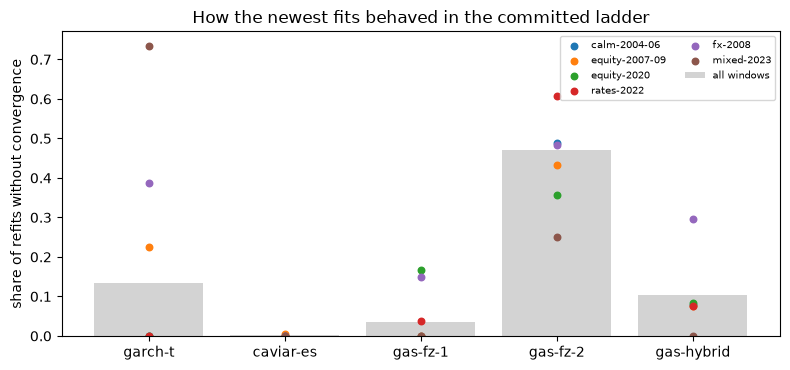

In [10]:
# The committed share of refits that did not converge, per rung and window, for the newest rungs and GARCH-t
fits = {e["model_id"]: {wf["window_id"]: wf for wf in e["window_fits"]} for e in ladder if e["window_fits"]}
rungs = ("garch-t", "caviar-es", "gas-fz-1", "gas-fz-2", "gas-hybrid")
share = {m: [fits[m][w]["n_convergence_failures"] / fits[m][w]["n_refits"] for w in NAMES] for m in rungs}
failures = {m: sum(fits[m][w]["n_convergence_failures"] for w in NAMES) for m in rungs}
total = {m: failures[m] / sum(fits[m][w]["n_refits"] for w in NAMES) for m in rungs}
for m in rungs:
    print(f"{m:11s} all windows {total[m]:.1%}")

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(range(len(rungs)), [total[m] for m in rungs], color="lightgrey", label="all windows")
for k, w in enumerate(NAMES):
    ax.scatter(range(len(rungs)), [share[m][k] for m in rungs], s=22, label=w)
ax.set_xticks(range(len(rungs)), rungs)
ax.set_ylabel("share of refits without convergence")
ax.set_title("How the newest fits behaved in the committed ladder")
ax.legend(fontsize=7, ncol=2)
fig.tight_layout()
plt.show()

The grey bars are the share of refits that did not converge over the six windows and the dots are the share in each window. The two-factor GAS-FZ failed in 47.2 percent of its refits, the hybrid in 10.4 percent and the one-factor model in 3.5 percent, while `caviar-es` failed in 0.1 percent. For comparison GARCH-t, which the engine fits through `arch`, failed in 13.4 percent, concentrated in `mixed-2023` and `fx-2008`. The record does not say how the pipeline handled a failed refit, only that the two-factor model is the least dependable to fit; it is the same rung that loses most clearly in the comparisons above. The figure supports reading the GAS-FZ results as evidence about the estimator as run here, with 20 starts and a refit every 20 days, and not about the model class.

### The quantile network trained on FZ0, run on a known truth

The neural challengers of the literature (the line of work after Patton, Ziegel and Chen 2019) train a network to output the VaR
and the ES directly, by minimising the FZ0 loss, which is strictly consistent for the pair. The product's rung R10 is the compact
form of that idea (`pipeline.cases.c11.quantile_net`): for each day the five previous returns and their absolute values divided by
the RiskMetrics volatility, and the log ratio of a fast to a slow volatility, feed a hidden layer of 8 units with two softplus
outputs, the VaR and the gap of the ES below it; the network minimises the mean FZ0 of the standardised returns on the 1,000-day
window before each forecast, refits every 20 days and keeps the best of three seeded starts. Its settings were fixed on 1995 to
2003, like every other rung's.

The returns of most C11 windows are derived-only and withheld from the repository, so this notebook measures the rung where the
answer is known: a GARCH(1,1) with Student-t shocks, whose VaR and ES are known every day. The network and two engine rungs, GARCH-t
(the model that generated the data) and EWMA, run on the same 1,000-day windows over the last 250 days.

In [ ]:
# Draw 1,250 days of a GARCH(1,1) with unit-variance Student-t shocks, whose daily VaR and ES at 2.5% are known
from scipy import stats

OMEGA, A1, B1, NU, ALPHA = 2e-6, 0.08, 0.90, 5.0, 0.025
n_days, window = 1250, 1000
rng = np.random.default_rng(20261030)
scale = np.sqrt((NU - 2) / NU)
shock = rng.standard_t(NU, n_days) * scale
sig2 = np.empty(n_days)
y = np.empty(n_days)
sig2[0] = OMEGA / (1 - A1 - B1)
for t in range(n_days):
    if t:
        sig2[t] = OMEGA + A1 * y[t - 1] ** 2 + B1 * sig2[t - 1]
    y[t] = np.sqrt(sig2[t]) * shock[t]
q = stats.t.ppf(ALPHA, NU)
var_unit = q * scale
es_unit = -stats.t.pdf(q, NU) / ALPHA * (NU + q * q) / (NU - 1) * scale
true_v = np.sqrt(sig2[window:]) * var_unit
true_e = np.sqrt(sig2[window:]) * es_unit
out = y[window:]
unit_label = "unit-variance quantile and expected shortfall"
days_label = "forecast days"
print(f"{unit_label}: VaR {var_unit:.4f}, ES {es_unit:.4f} | {days_label}: {out.size}")


The unit-variance quantile at 2.5 % of a Student-t with 5 degrees of freedom is -1.99, close to the normal -1.96, but its
expected shortfall is fatter than the normal's. The next cell forecasts each of the last 250 days from the 1,000 days before it:
the network refits every 20 days, as in the product, and so does GARCH-t, while EWMA updates every day; each forecast is scored
against the realised return with the engine's FZ0 loss, and against the true VaR.

In [ ]:
# Forecast the 250 days with the network of rung R10, the engine's GARCH-t and EWMA, each on its 1,000-day window
from riskvalidation.market import garch, parametric
from riskvalidation.market.scoring import fz0_loss

from pipeline.cases.c11 import quantile_net as qn

rows = {"nn-fz (R10)": ([], []), "garch-t": ([], []), "ewma": ([], [])}
for i in range(window, n_days):
    win = y[i - window:i]
    if (i - window) % qn.NET.refit_every_days == 0:
        fit_nn = qn.fit_net(win, ALPHA, qn.NET, seed=11)
        fit_g = garch.fit_garch(win, "garch", "student-t", "constant")
    forecasts = (qn.predict(fit_nn, win), garch.garch_var_es_forecast(fit_g, win, ALPHA),
                 parametric.ewma_var_es(win, 0.94, ALPHA, float(np.var(win[:20]))))
    for name, (v, e) in zip(rows, forecasts):
        rows[name][0].append(v)
        rows[name][1].append(e)
truth_fz0 = np.mean(fz0_loss(out, true_v, true_e, ALPHA))
truth_label = "truth"
exc_label = "exceedances"
gap_label = "mean |VaR / true VaR - 1|"
print(f"{truth_label:14s} {exc_label} {int((out < true_v).sum()):3d} | FZ0 {truth_fz0:.4f}")
for name, (v, e) in rows.items():
    v, e = np.array(v), np.array(e)
    gap = np.mean(np.abs(v / true_v - 1))
    score = np.mean(fz0_loss(out, v, e, ALPHA))
    print(f"{name:14s} {exc_label} {int((out < v).sum()):3d} | FZ0 {score:.4f} | {gap_label} {gap:.3f}")


The true VaR is exceeded 4 times in 250 days against 6.25 expected, the sampling noise of a year. GARCH-t, the model that
drew the data, has the same 4 exceedances and a VaR within 3.8 % of the truth on average; EWMA is within 7.4 %. The network is
exceeded 25 times and its VaR is 39.7 % too small on average, so its average FZ0, 0.0587, is far above the -3.88 of GARCH-t and the
-3.90 of the truth: the loss punishes a VaR that is too close to zero. The figure shows where the gap comes from.

In [ ]:
# Draw the 250 forecast days: the returns, the true VaR and the VaR of the network and of GARCH-t
days = np.arange(out.size)
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(days, 100 * out, color="lightgrey", linewidth=0.8, label="daily return")
ax.plot(days, 100 * true_v, color="black", label="true VaR at 2.5%")
ax.plot(days, 100 * np.array(rows["nn-fz (R10)"][0]), color="tab:red", label="nn-fz (R10)")
ax.plot(days, 100 * np.array(rows["garch-t"][0]), "--", color="tab:blue", label="garch-t")
ax.set_xlabel("forecast day")
ax.set_ylabel("percent of value")
ax.set_title("One-day VaR at 2.5% on a known GARCH-t")
ax.legend(fontsize=8, ncol=4)
fig.tight_layout()
plt.show()


The network's VaR tracks the volatility, so its timing is right: it widens and narrows with the true VaR. Its level is wrong,
a band about a third narrower than the truth, and it is exceeded on most of the days the true VaR nearly is. With 1,000 days and a
2.5 % tail the network sees about 25 tail observations per fit; the FZ0 gradient comes almost entirely from them, and eight hidden
units fitted to so few points learn the body of the distribution better than its tail. GARCH-t has the right parametric family and
needs no tail observations to set its quantile. The product's run on the real windows shows the same behaviour.

In [ ]:
# The product's own run of R10: its eligibility and the champion at 2.5% in each of the six windows
eligible_label = "eligible"
hits_label = "exceedances at 1% / expected"
champion_label = "champion at 2.5%"
for w in NAMES:
    o = docs[w]["outputs"]
    nn = next(m for m in o["models"] if m["model_id"] == "nn-fz")
    champion = next((c for c in o["comparison"]["champions"] if c["alpha"] == ALPHA), {}).get("model_id")
    level = next(lv for lv in nn["by_level"] if lv["alpha"] == 0.01)
    hits = f"{level['n_exceedances']} / {level['expected_exceedances']:.1f}"
    flag = str(nn["eligible"])
    print(f"{w:15s} R10 {eligible_label} {flag:5s} | {hits_label} {hits:9s} | {champion_label} {champion}")


On the product's six windows the network passes every eligibility gate only in fx-2008 and mixed-2023 and is the champion
in none: it is exceeded 22 times at 1 % in the calm window where 7.5 are expected, the same narrow tail the known truth showed, and
the champions are EWMA, EVT and GJR-t. The product replicated the network as the plan asked (trained, gated and ranked like every
other rung) and reports that, at this size, it does not beat the econometric rungs; a larger network or a longer window is a change
of method that would have to be fixed before the test windows, not tuned on them.

## Results

**Answer:** No. In six windows the newest rungs do not rank consistently above the econometric ones: `caviar-es` is indistinguishable from `ewma` and `evt-mf` in 8 of 8 comparisons, and the three GAS-FZ rungs have the higher loss in 24 of 24 comparisons, 12 of them significant and none significantly better, with no GAS-FZ rung among the first six of any window. The engine's GARCH-t fit equals the `arch` reference on `fx-2008` (log-likelihood 803.654204 in both, a relative difference of 0.00e+00 in every parameter), which checks the engine's wrapper and not `arch` itself.

- **Ranks.** Among the 14 rungs with an ES, at 1 percent, `caviar-es` ranks 7, 5, 3, 5, 1 and 7 in the six windows (first in `fx-2008`); `gas-fz-1` ranks 11, 11, 9, 13, 14 and 9; `gas-fz-2` 12, 10, 10, 12, 12 and 11; `gas-hybrid` 13, 13, 7, 11, 13 and 8. The best rung is `gjr-t` in three windows, `fhs` in `equity-2020`, `ewma` in `rates-2022` and `caviar-es` in `fx-2008`.
- **The tests agree with the ranks.** Of the 24 comparisons of the GAS-FZ rungs with the two references 24 have the higher loss and 12 are significant at 5 percent; 0 newest rungs are significantly better.
- **The confidence set.** At 1 percent in `fx-2008` the set holds 13 of 14 rungs and excludes only `dn-rolling`; the four newest are inside, with MCS p-values of 1.000 (`caviar-es`), 0.678, 0.493 and 0.644.
- **How the fits behaved.** Over the six windows 47.2 percent of the refits of `gas-fz-2` did not converge, 10.4 percent of `gas-hybrid`, 3.5 percent of `gas-fz-1` and 0.1 percent of `caviar-es`; GARCH-t failed in 13.4 percent.
- **The GARCH-t fit against `arch`.** The engine and `arch` return the same five parameters and the log-likelihood 803.654204; from a second starting point `arch` is 8.26e-08 away in log-likelihood and 1.15e-04 relative in the parameters, inside the stated tolerances. `rates-2022` commits 249 returns, one fewer than the engine's minimum of 250.
- **What the evidence supports.** On these windows, with the product's estimation settings, the dynamic semiparametric rungs did not beat the econometric ones and CAViaR-ES matched them. The evidence is six windows at two levels with 64 to 750 days; it does not support a claim about those methods in general, and it is silent on a neural model, which was not run.

What this notebook does not show: any new component of Contraste beyond this practice; those are in the level 4 notebooks of the topics that carry a claim.

The quantile network trained on FZ0 (rung R10) does not beat the econometric rungs: on a known GARCH-t it is exceeded
25 times in 250 days against 6.25 expected and its VaR is 39.7 % too small on average, while GARCH-t is within 3.8 %; on the six
windows of the product it is eligible in 2 and the champion in none.

## Summary

- The newest methods for VaR and ES model the pair jointly and let it evolve with the data: GAS-FZ and its hybrid minimise the FZ0 loss itself, CAViaR-ES adds an ES to a quantile recursion, and neural quantile models are a line of preprints.
- The comparative-backtest frame asks whether a challenger beats a standard model under a consistent loss, not only whether the champion is rejected; Contraste uses it after the traditional backtests have decided eligibility.
- On six committed market windows the newest rungs do not rank consistently above the econometric ones: Diebold-Mariano finds no newest rung significantly better, and the GAS-FZ rungs are the least stable in the record of their fits.
- The model confidence set at 1 percent in `fx-2008` keeps all four newest rungs in, so the pairwise tests and the set answer different questions with the same data.
- The neural challenger is recorded as not run, so the ladder offers no evidence about it; it would have to enter the 90 percent confidence set out of sample.
- The engine's GARCH-t fit equals a direct `arch` call on the committed `fx-2008` returns to the printed digits and does not depend on the optimiser's start; that checks the engine's wrapper, not `arch`.

**What to try next.** Recompute the table of step 2 at the other level in `rates-2022` with a different reference and name the window and level in which a newest rung is significantly better, if any; then read the case page of C11 for the full ladder.

- The FZ0-trained network of rung R10 follows the volatility but under-states the tail: 25 exceedances against 6.25 expected on a known truth, and no window won on the product's data.

## References

- Patton, A. J., Ziegel, J. F. and Chen, R. (2019), Dynamic semiparametric models for expected shortfall (and value-at-risk), Journal of Econometrics 211(2). https://doi.org/10.1016/j.jeconom.2018.10.008 (preprint https://arxiv.org/abs/1707.05108)
- Taylor, J. W. (2019), Forecasting value at risk and expected shortfall using a semiparametric approach based on the asymmetric Laplace distribution, Journal of Business and Economic Statistics 37(1). https://doi.org/10.1080/07350015.2017.1281815
- Nolde, N. and Ziegel, J. F. (2017), Elicitability and backtesting: perspectives for banking regulation, Annals of Applied Statistics 11(4). https://doi.org/10.1214/17-AOAS1041
- Kratz, M., Lok, Y. H. and McNeil, A. J. (2018), Multinomial VaR backtests: a simple implicit approach to backtesting expected shortfall, Journal of Banking and Finance 88. https://doi.org/10.1016/j.jbankfin.2018.01.002
- Diebold, F. X. and Mariano, R. S. (1995), Comparing predictive accuracy, Journal of Business and Economic Statistics 13(3). https://doi.org/10.1080/07350015.1995.10524599
- Hansen, P. R., Lunde, A. and Nason, J. M. (2011), The model confidence set, Econometrica 79(2). https://doi.org/10.3982/ECTA5771
- A neural joint VaR and ES network trained on the FZ loss (preprint, challenger only). https://arxiv.org/abs/2606.04576